# CardioIA Fase 4: Parte 2, Transfer Learning com ResNet50 e comparação das abordagens

**Curso:** Inteligência Artificial, FIAP, turma 2TIAOR, Fase 4, Cap 1 (Visão Computacional na Clínica)
**Autor:** Silvio Prestes Guerreiro Junior, RM 567958

> **Aviso:** protótipo acadêmico, sem validade diagnóstica. Nenhum resultado deste notebook deve orientar conduta clínica.

## Objetivo

Aplicar Transfer Learning com a **ResNet50** pré-treinada no ImageNet ao mesmo problema (Cardiomegalia x Sem achado), nas duas etapas apresentadas no Cap 11, extração de características e ajuste fino, e comparar o resultado com a CNN treinada do zero no mesmo conjunto de teste.

**Por que ResNet50:** é uma das arquiteturas trabalhadas em aula e citadas no enunciado, tem pesos públicos (licença Apache 2.0 no Keras Applications) e as conexões residuais permitem uma rede profunda que treina de forma estável.

## 1. Configuração e leitura dos dados

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_PROC, DIR_PRINT, DIR_MOD = RAIZ / "data" / "processed", RAIZ / "prints", RAIZ / "models"
IMG_SIZE, BATCH = 224, 32
CLASSES = ["sem_achado", "cardiomegalia"]
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "nenhuma (treino em CPU)")

TensorFlow 2.21.0 | GPU: nenhuma (treino em CPU)


**Normalização específica do modelo pré-treinado.** Na CNN do zero os pixels foram reescalados para [0, 1]. Um modelo pré-treinado precisa receber as imagens com a **mesma normalização usada no seu treino original**. Para a ResNet50 do Keras isso é feito pela função `preprocess_input`, que converte RGB em BGR e subtrai a média de cada canal do ImageNet. Usar outra normalização degradaria as características já aprendidas. O aumento de dados, aplicado só no treino, é o mesmo da Parte 1.

In [2]:
gen_treino = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=7, width_shift_range=0.05,
                                height_shift_range=0.05, zoom_range=0.10, fill_mode="constant", cval=0)
gen_aval = ImageDataGenerator(preprocessing_function=preprocess_input)
kw = dict(target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb", class_mode="binary", classes=CLASSES, batch_size=BATCH, seed=SEED)
treino = gen_treino.flow_from_directory(DIR_PROC / "train", shuffle=True, **kw)
val    = gen_aval.flow_from_directory(DIR_PROC / "val", shuffle=False, **kw)
teste  = gen_aval.flow_from_directory(DIR_PROC / "test", shuffle=False, **kw)

Found 3928 images belonging to 2 classes.


Found 805 images belonging to 2 classes.


Found 819 images belonging to 2 classes.


## 2. Modelo: base pré-treinada e nova cabeça de classificação

- **Base:** ResNet50 com pesos do ImageNet, sem as camadas finais de classificação (`include_top=False`).
- **Cabeça nova:** `GlobalAveragePooling2D` (resume cada mapa de ativação em um número, com muito menos parâmetros que um Flatten), `Dropout` de 50%, uma camada densa de 256 neurônios e a saída sigmoide.
- A base é chamada com `training=False`, de modo que as camadas de Batch Normalization continuam usando as estatísticas do ImageNet mesmo durante o ajuste fino. Atualizá-las com lotes pequenos de um domínio novo costuma desestabilizar o treino.

In [3]:
base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False                                   # etapa 1: toda a base congelada

entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base(entrada, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation="relu")(x)
saida = layers.Dense(1, activation="sigmoid")(x)
modelo = models.Model(entrada, saida, name="resnet50_transfer")

def compilar(lr):
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                   metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Recall(name="recall")])

def contar():
    tr = int(sum(np.prod(w.shape) for w in modelo.trainable_weights)); tot = int(modelo.count_params())
    return tr, tot

compilar(1e-3)
tr1, tot = contar()
print(f"Camadas na base: {len(base.layers)} | parâmetros totais: {tot:,} | treináveis na etapa 1: {tr1:,} ({tr1/tot:.1%})")

Camadas na base: 175 | parâmetros totais: 24,112,513 | treináveis na etapa 1: 524,801 (2.2%)


## 3. Etapa 1: extração de características (base congelada)

Só a cabeça nova é treinada. A ResNet50 funciona como um extrator fixo de características visuais gerais (bordas, texturas, formas) aprendidas no ImageNet. Taxa de aprendizado de 0,001, com parada antecipada pela perda de validação.

In [4]:
def cbs(nome, paciencia):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
            callbacks.ModelCheckpoint(DIR_MOD / nome, monitor="val_loss", save_best_only=True)]

t0 = time.time()
h1 = modelo.fit(treino, validation_data=val, epochs=15, callbacks=cbs("resnet50_etapa1.keras", 4), verbose=2)
t1 = time.time() - t0
h1 = pd.DataFrame(h1.history); h1.index += 1
val1 = modelo.evaluate(val, verbose=0, return_dict=True)
print(f"\nEtapa 1: {t1/60:.1f} min, {len(h1)} épocas. Validação com os melhores pesos:", {k: round(v, 4) for k, v in val1.items()})

Epoch 1/15


123/123 - 100s - 812ms/step - accuracy: 0.6408 - auc: 0.6832 - loss: 0.7222 - recall: 0.6534 - val_accuracy: 0.7068 - val_auc: 0.8071 - val_loss: 0.5605 - val_recall: 0.8689 - learning_rate: 0.0010


Epoch 2/15


123/123 - 97s - 792ms/step - accuracy: 0.6993 - auc: 0.7638 - loss: 0.5847 - recall: 0.7068 - val_accuracy: 0.7168 - val_auc: 0.8123 - val_loss: 0.5475 - val_recall: 0.5784 - learning_rate: 0.0010


Epoch 3/15


123/123 - 99s - 808ms/step - accuracy: 0.7065 - auc: 0.7724 - loss: 0.5700 - recall: 0.7149 - val_accuracy: 0.7255 - val_auc: 0.8093 - val_loss: 0.5352 - val_recall: 0.7918 - learning_rate: 0.0010


... (11 outputs left out)

123/123 - 88s - 718ms/step - accuracy: 0.7319 - auc: 0.8120 - loss: 0.5291 - recall: 0.7486 - val_accuracy: 0.7329 - val_auc: 0.8266 - val_loss: 0.5222 - val_recall: 0.8432 - learning_rate: 5.0000e-04


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 4.



Etapa 1: 12.4 min, 8 épocas. Validação com os melhores pesos: {'accuracy': 0.7304, 'auc': 0.8225, 'loss': 0.519, 'recall': 0.7532}


## 4. Etapa 2: ajuste fino (fine-tuning)

Radiografias são muito diferentes das fotos do ImageNet, então vale adaptar as camadas mais profundas da base, que guardam as características mais específicas. Nesta etapa:

- **descongelado:** o último estágio residual da ResNet50 (camadas `conv5_*`), exceto as de Batch Normalization;
- **mantido congelado:** todos os estágios anteriores (`conv1` a `conv4`), que guardam características genéricas, e todas as camadas de Batch Normalization;
- **taxa de aprendizado 100 vezes menor** (0,00001), para refinar os pesos sem destruir o que já foi aprendido (esquecimento catastrófico).

In [5]:
base.trainable = True
for camada in base.layers:
    camada.trainable = camada.name.startswith("conv5") and not isinstance(camada, layers.BatchNormalization)
compilar(1e-5)
tr2, _ = contar()
n_desc = sum(c.trainable for c in base.layers)
print(f"Camadas da base descongeladas: {n_desc} de {len(base.layers)} | parâmetros treináveis na etapa 2: {tr2:,} ({tr2/tot:.1%})")

t0 = time.time()
h2 = modelo.fit(treino, validation_data=val, epochs=15, callbacks=cbs("resnet50_etapa2.keras", 4), verbose=2)
t2 = time.time() - t0
h2 = pd.DataFrame(h2.history); h2.index += len(h1) + 1
val2 = modelo.evaluate(val, verbose=0, return_dict=True)
print(f"\nEtapa 2: {t2/60:.1f} min, {len(h2)} épocas. Validação com os melhores pesos:", {k: round(v, 4) for k, v in val2.items()})

Camadas da base descongeladas: 22 de 175 | parâmetros treináveis na etapa 2: 15,478,273 (64.2%)


Epoch 1/15


123/123 - 133s - 1s/step - accuracy: 0.7393 - auc: 0.8144 - loss: 0.5264 - recall: 0.7597 - val_accuracy: 0.7602 - val_auc: 0.8460 - val_loss: 0.4927 - val_recall: 0.8560 - learning_rate: 1.0000e-05


Epoch 2/15


123/123 - 136s - 1s/step - accuracy: 0.7793 - auc: 0.8605 - loss: 0.4641 - recall: 0.7960 - val_accuracy: 0.7814 - val_auc: 0.8674 - val_loss: 0.4736 - val_recall: 0.8817 - learning_rate: 1.0000e-05


Epoch 3/15


... (14 outputs left out)

123/123 - 123s - 997ms/step - accuracy: 0.8768 - auc: 0.9529 - loss: 0.2775 - recall: 0.8730 - val_accuracy: 0.8062 - val_auc: 0.8909 - val_loss: 0.4556 - val_recall: 0.8201 - learning_rate: 5.0000e-06


Epoch 9: early stopping


Restoring model weights from the end of the best epoch: 5.



Etapa 2: 19.2 min, 9 épocas. Validação com os melhores pesos: {'accuracy': 0.7988, 'auc': 0.8837, 'loss': 0.4465, 'recall': 0.8535}


Perda de validação: etapa 1 = 0.519 | etapa 2 = 0.4465 | modelo final: etapa 2 (ajuste fino)


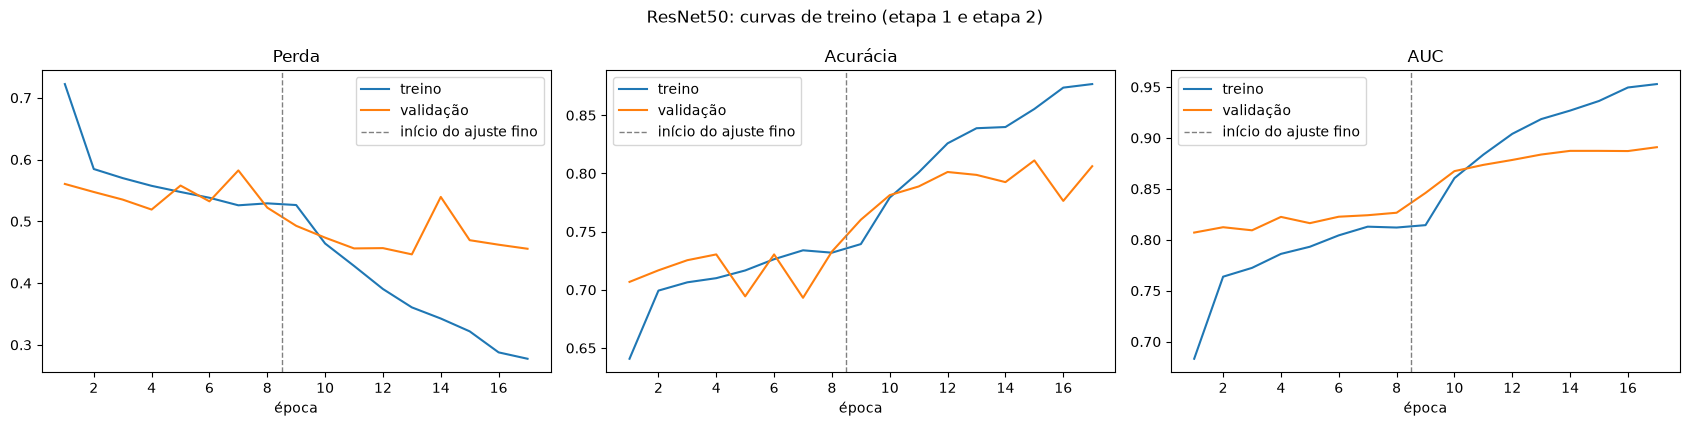

In [6]:
# Escolha do modelo final pela VALIDAÇÃO (o teste não participa da escolha)
usar2 = val2["loss"] < val1["loss"]
escolhido = "etapa 2 (ajuste fino)" if usar2 else "etapa 1 (extração de características)"
if not usar2:
    modelo = tf.keras.models.load_model(DIR_MOD / "resnet50_etapa1.keras")
modelo.save(DIR_MOD / "resnet50_final.keras")
print("Perda de validação: etapa 1 =", round(val1["loss"], 4), "| etapa 2 =", round(val2["loss"], 4), "| modelo final:", escolhido)

h = pd.concat([h1, h2]); h.to_csv(RAIZ / "data" / "historico_resnet50.csv", index_label="epoca")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for a, (m, t) in zip(ax, [("loss", "Perda"), ("accuracy", "Acurácia"), ("auc", "AUC")]):
    a.plot(h.index, h[m], label="treino"); a.plot(h.index, h["val_" + m], label="validação")
    a.axvline(len(h1) + 0.5, color="gray", ls="--", lw=1, label="início do ajuste fino"); a.set_title(t); a.set_xlabel("época"); a.legend()
plt.suptitle("ResNet50: curvas de treino (etapa 1 e etapa 2)"); plt.tight_layout()
plt.savefig(DIR_PRINT / "10_resnet_curvas_treino.png", dpi=130); plt.show()

## 5. Avaliação no conjunto de teste

In [7]:
def avaliar(y, p, limiar=0.5):
    yp = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
    return {"limiar": round(float(limiar), 3), "acuracia": accuracy_score(y, yp), "precisao": precision_score(y, yp),
            "recall": recall_score(y, yp), "f1": f1_score(y, yp), "especificidade": tn / (tn + fp),
            "auc": roc_auc_score(y, p), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

p_val, y_val = modelo.predict(val, verbose=0).ravel(), val.classes
p_test, y_test = modelo.predict(teste, verbose=0).ravel(), teste.classes
r05 = avaliar(y_test, p_test, 0.5)
print(pd.Series(r05).round(4).to_string())
print("\n", classification_report(y_test, (p_test >= 0.5).astype(int), target_names=CLASSES, digits=4))

# limiar sensível, escolhido na validação (mesmo critério do notebook 02)
cand = np.round(np.arange(0.05, 0.96, 0.01), 2)
rec_val = np.array([recall_score(y_val, (p_val >= c).astype(int)) for c in cand])
limiar_sens = float(cand[rec_val >= 0.90].max())
rs = avaliar(y_test, p_test, limiar_sens)

limiar              0.5000
acuracia            0.8071
precisao            0.7699
recall              0.8657
f1                  0.8150
especificidade      0.7506
auc                 0.8816
tn                313.0000
fp                104.0000
fn                 54.0000
tp                348.0000

                precision    recall  f1-score   support

   sem_achado     0.8529    0.7506    0.7985       417
cardiomegalia     0.7699    0.8657    0.8150       402

     accuracy                         0.8071       819
    macro avg     0.8114    0.8081    0.8067       819
 weighted avg     0.8121    0.8071    0.8066       819



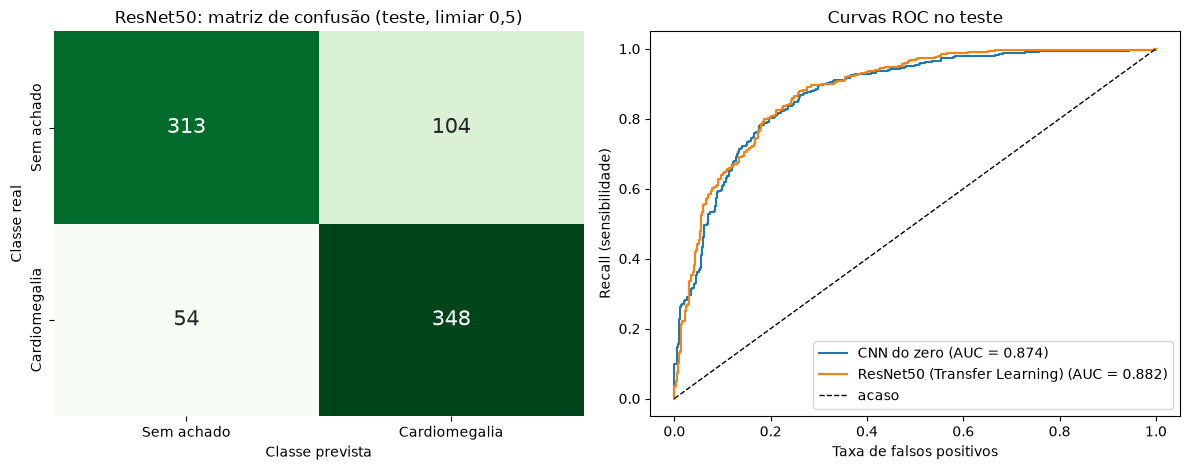

In [8]:
cnn = json.loads((RAIZ / "data" / "resultados_cnn_do_zero.json").read_text())
pc = pd.read_csv(RAIZ / "data" / "pred_teste_cnn_do_zero.csv")
assert (pc.y.values == y_test).all(), "os dois modelos devem ser avaliados nas mesmas imagens, na mesma ordem"

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(confusion_matrix(y_test, (p_test >= 0.5).astype(int)), annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[0], annot_kws={"size": 15},
            xticklabels=["Sem achado", "Cardiomegalia"], yticklabels=["Sem achado", "Cardiomegalia"])
ax[0].set_xlabel("Classe prevista"); ax[0].set_ylabel("Classe real"); ax[0].set_title("ResNet50: matriz de confusão (teste, limiar 0,5)")
for nome, p in [("CNN do zero", pc.prob.values), ("ResNet50 (Transfer Learning)", p_test)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[1].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="acaso"); ax[1].set_xlabel("Taxa de falsos positivos"); ax[1].set_ylabel("Recall (sensibilidade)")
ax[1].set_title("Curvas ROC no teste"); ax[1].legend()
plt.tight_layout(); plt.savefig(DIR_PRINT / "11_resnet_matriz_confusao_roc.png", dpi=130); plt.show()

## 6. Comparação das duas abordagens

As duas redes foram avaliadas nas mesmas 819 imagens de teste, com o mesmo critério.

In [9]:
cols = ["acuracia", "precisao", "recall", "f1", "especificidade", "auc", "fn", "fp"]
comp = pd.DataFrame({"CNN do zero": cnn["teste_limiar_0.5"], "ResNet50 (Transfer Learning)": r05}).T[cols]
comp[["fn", "fp"]] = comp[["fn", "fp"]].astype(int)
extra = pd.DataFrame({"parametros": [cnn["parametros"], tot], "epocas": [cnn["epocas"], len(h)],
                      "tempo_treino_min": [cnn["tempo_treino_min"], round((t1 + t2) / 60, 1)]}, index=comp.index)
print(extra.to_string(), "\n")
comp.round(4)

                              parametros  epocas  tempo_treino_min
CNN do zero                      3452353      40              33.1
ResNet50 (Transfer Learning)    24112513      17              31.6 



,acuracia,precisao,recall,f1,especificidade,auc,fn,fp
CNN do zero,0.7985,0.7869,0.8085,0.7975,0.7890,0.8742,77,88
ResNet50 (Transfer Learning),0.8071,0.7699,0.8657,0.8150,0.7506,0.8816,54,104


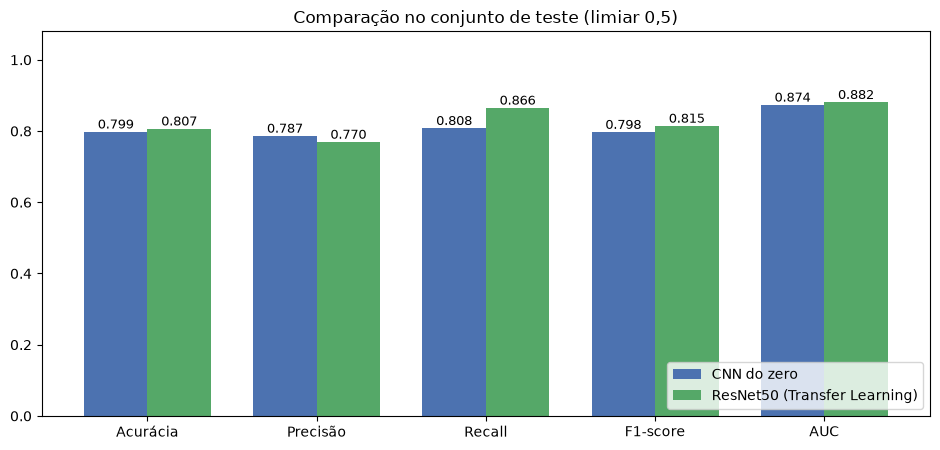

Com limiar sensível (recall de pelo menos 90% na validação):


,limiar,acuracia,precisao,recall,f1,especificidade,auc,fn,fp
CNN do zero,0.36,0.7937,0.7432,0.8856,0.8082,0.7050,0.8742,46.0,123.0
ResNet50 (Transfer Learning),0.41,0.7973,0.7438,0.8955,0.8126,0.7026,0.8816,42.0,124.0


In [10]:
m = ["acuracia", "precisao", "recall", "f1", "auc"]
ax = comp[m].astype(float).T.plot.bar(figsize=(9.5, 4.6), rot=0, color=["#4C72B0", "#55A868"], width=0.75)
ax.set_xticklabels(["Acurácia", "Precisão", "Recall", "F1-score", "AUC"]); ax.set_ylim(0, 1.08); ax.set_title("Comparação no conjunto de teste (limiar 0,5)")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(DIR_PRINT / "12_comparacao_modelos.png", dpi=130); plt.show()

comp_s = pd.DataFrame({"CNN do zero": cnn["teste_limiar_sensivel"], "ResNet50 (Transfer Learning)": rs}).T[["limiar"] + cols]
print("Com limiar sensível (recall de pelo menos 90% na validação):")
comp_s.round(4)

In [11]:
arqs = np.array(teste.filepaths)
pd.DataFrame({"arquivo": [str(Path(a).relative_to(DIR_PROC)) for a in arqs], "y": y_test, "prob": p_test}).to_csv(RAIZ / "data" / "pred_teste_resnet50.csv", index=False)
pd.DataFrame({"arquivo": [str(Path(a).relative_to(DIR_PROC)) for a in val.filepaths], "y": y_val, "prob": p_val}).to_csv(RAIZ / "data" / "pred_val_resnet50.csv", index=False)
res = {"modelo": "resnet50_transfer", "modelo_final": escolhido, "parametros": tot, "treinaveis_etapa1": tr1, "treinaveis_etapa2": tr2,
       "camadas_base": len(base.layers), "camadas_descongeladas": int(n_desc), "epocas_etapa1": len(h1), "epocas_etapa2": len(h2),
       "tempo_treino_min": round((t1 + t2) / 60, 1), "val_etapa1": val1, "val_etapa2": val2,
       "teste_limiar_0.5": r05, "teste_limiar_sensivel": rs, "tensorflow": tf.__version__, "seed": SEED}
(RAIZ / "data" / "resultados_resnet50.json").write_text(json.dumps(res, indent=2, default=float))
comp.to_csv(RAIZ / "data" / "comparacao_modelos.csv")
print(json.dumps(res, indent=2, default=float))

{
  "modelo": "resnet50_transfer",
  "modelo_final": "etapa 2 (ajuste fino)",
  "parametros": 24112513,
  "treinaveis_etapa1": 524801,
  "treinaveis_etapa2": 15478273,
  "camadas_base": 175,
  "camadas_descongeladas": 22,
  "epocas_etapa1": 8,
  "epocas_etapa2": 9,
  "tempo_treino_min": 31.6,
  "val_etapa1": {
    "accuracy": 0.730434775352478,
    "auc": 0.8224892616271973,
    "loss": 0.5190271735191345,
    "recall": 0.7532133460044861
  },
  "val_etapa2": {
    "accuracy": 0.798757791519165,
    "auc": 0.8837100863456726,
    "loss": 0.44649460911750793,
    "recall": 0.8534704446792603
  },
  "teste_limiar_0.5": {
    "limiar": 0.5,
    "acuracia": 0.8070818070818071,
    "precisao": 0.7699115044247787,
    "recall": 0.8656716417910447,
    "f1": 0.8149882903981265,
    "especificidade": 0.750599520383693,
    "auc": 0.8816170943841941,
    "tn": 313,
    "fp": 104,
    "fn": 54,
    "tp": 348
  },
  "teste_limiar_sensivel": {
    "limiar": 0.41,
    "acuracia": 0.7973137973137974

## 7. Análise dos resultados

Todos os números vêm da execução gravada neste notebook e nos notebooks `02` e `03b`.

**O que foi congelado e o que foi ajustado.** A ResNet50 tem 175 camadas e 24,1 milhões de parâmetros no modelo completo. Na etapa 1 toda a base ficou congelada e só a cabeça nova foi treinada (524.801 parâmetros, 2,2% do total). Na etapa 2 foram descongeladas 22 camadas do último estágio residual (`conv5`), o que elevou os parâmetros treináveis para 15,5 milhões (64,2%), com taxa de aprendizado de 0,00001. Os estágios `conv1` a `conv4` e todas as camadas de Batch Normalization permaneceram congelados.

**Efeito de cada etapa.** Só com a extração de características (8 épocas) a rede chegou a 73,0% de acurácia e AUC de 0,822 na validação, abaixo da CNN do zero. As características do ImageNet, aprendidas em fotos coloridas de objetos, transferem-se mal para radiografias sem adaptação. O ajuste fino (9 épocas) levou a validação a 79,9% de acurácia e AUC de 0,884. O modelo final, escolhido pela perda de validação, é o da etapa 2. O treino completo levou 31,6 minutos em CPU.

**Overfitting no ajuste fino.** A partir da segunda metade da etapa 2 a acurácia de treino continuou subindo (87,7% na última época) enquanto a de validação ficou perto de 80%. A parada antecipada restaurou os pesos da quinta época do ajuste fino, antes de a diferença crescer. Com 3.928 imagens de treino, liberar 15 milhões de parâmetros exige esse controle.

**Comparação no teste (limiar 0,5).**

| Métrica | CNN do zero | ResNet50 |
|---|---|---|
| Acurácia | 79,9% | 80,7% |
| Precisão | 78,7% | 77,0% |
| Recall | 80,8% | 86,6% |
| F1-score | 79,8% | 81,5% |
| Especificidade | 78,9% | 75,1% |
| AUC | 0,874 | 0,882 |
| Falsos negativos | 77 | 54 |
| Falsos positivos | 88 | 104 |

**A diferença é pequena e, na maior parte, não é estatisticamente distinguível.** O notebook `03b_comparacao_estatistica.ipynb` calculou intervalos de confiança por bootstrap sobre pacientes. As diferenças de acurácia (+0,9 ponto), F1 (+1,7) e AUC (+0,007) têm intervalos que incluem o zero, e o teste de McNemar para a acurácia deu p = 0,61. A única diferença sustentada é o recall no limiar 0,5 (+5,7 pontos, intervalo de +2,0 a +9,9), que vem acompanhada de queda na especificidade. Ou seja, com o limiar 0,5 a ResNet50 opera em um ponto mais sensível da curva, e não em uma curva claramente melhor. Quando os dois modelos são colocados no mesmo critério (limiar escolhido na validação para recall de 90%), ficam quase iguais: 42 falsos negativos e 124 falsos positivos na ResNet50, contra 46 e 123 na CNN.

**Conclusão honesta.** Neste problema e com este volume de dados, o Transfer Learning não trouxe o ganho expressivo que costuma trazer em fotos comuns. Três fatores explicam: a distância entre o domínio do ImageNet e o de radiografias; o ruído dos rótulos do NIH, que impõe um teto às duas redes; e a resolução de 224 pixels. A ResNet50 chegou ao resultado em menos épocas (17 contra 40) e foi escolhida para o protótipo por ter o maior AUC de validação e o maior recall, que é a métrica prioritária em triagem. A CNN do zero, sete vezes menor (3,45 milhões de parâmetros), é uma alternativa válida quando o custo computacional pesar.

**Uso clínico.** Com limiar 0,5 a ResNet50 ainda deixa passar 54 de 402 casos de Cardiomegalia (13,4%). Com o limiar de 0,41 esse número cai para 42 (10,4%), com 124 falsos positivos. Nenhum dos dois pontos é aceitável para uso sem revisão médica. O protótipo adota três faixas (sem achado, inconclusivo e sugestivo) justamente para sinalizar a zona em que o modelo erra mais.

**Limitações.** As mesmas da CNN do zero: conjunto balanceado artificialmente, rótulos com ruído, um único hospital, ausência de explicação visual da decisão. Além disso, cada modelo foi treinado uma única vez (semente 42); repetir com outras sementes daria uma medida da variação entre treinos, que aqui não foi estimada.